# Compare pytse-client with www.tsetmc.com

Run the cells one by one. Each section fetches one thing for the symbol **فولاد** with
pytse-client, prints it the way the website shows it, and says which page, tab and box of
www.tsetmc.com shows the same numbers. Open the link, find the box, compare.

The website writes numbers like this, and so does this notebook: `1.823 B` is 1,823 million
(billion), `863.466 M` is 863.466 million, smaller numbers get thousands separators, dates
are Jalali (1405/08/26), negative changes are shown in parentheses.

**How to run** (from the root of the repository):

```sh
mise install && uv sync
uv run --with jupyterlab jupyter lab tests/manual/compare_with_website.ipynb
```

or open this file in VS Code or PyCharm and pick the `.venv` of the repository as kernel.

**Good to know**

* During trading hours (Saturday to Wednesday, 09:00 to 12:30 Tehran time) the live numbers
  change every few seconds. Compare right after running a cell, or run it when the market
  is closed.
* The screenshots at the end of the notebook were taken on 1405/08/26 (2026-11-17) after the
  market closed. They show where each number is on the page; their numbers are from that day.
* Some functions of pytse-client use `asyncio.run`, which cannot run inside Jupyter's own
  event loop. The notebook runs those in a separate thread (`in_thread`) or awaits their
  `_async` version.

In [ ]:
import datetime
import pathlib
import re
from concurrent.futures import ThreadPoolExecutor

import jdatetime
import pandas as pd
from IPython.display import Markdown, display

import pytse_client as tse
from pytse_client import FinancialIndex, Ticker, symbols_data
from pytse_client.scraper.symbol_scraper import get_symbol_info

SYMBOL = "فولاد"
ticker = Ticker(SYMBOL)
INDEX = ticker.index
PAGE = ticker.url  # https://www.tsetmc.com/instInfo/46348559193224090

pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 200)


def site(number):
    """Format a number like the website: 1.823 B, 863.466 M, 5,120."""
    if number is None or pd.isna(number):
        return None
    number = float(number)
    for size, unit in ((1e9, "B"), (1e6, "M")):
        if abs(number) >= size:
            return f"{number / size:,.3f}".rstrip("0").rstrip(".") + f" {unit}"
    return f"{number:,.0f}" if number == int(number) else f"{number:,.2f}"


def price(number):
    return None if number is None else f"{number:,.0f}"


def decimal(number):
    """5,120.5 like the website, no trailing zeros"""
    return None if number is None else f"{number:,.2f}".rstrip("0").rstrip(".")


def rounded(number):
    return None if number is None else round(number, 2)


def jalali(day):
    """Gregorian date (or YYYYMMDD string) to the Jalali date the website shows."""
    return jdatetime.date.fromgregorian(date=pd.Timestamp(day).date()).strftime("%Y/%m/%d")


def where(url, place):
    display(Markdown(f"**Open:** [{url}]({url})<br>**Look at:** {place}"))


def compare(rows):
    """rows of (label on the website, value from pytse-client, python code)"""
    display(pd.DataFrame(rows, columns=["label on the website", "pytse-client", "python"]))


def in_thread(function, *args, **kwargs):
    """Run a function that uses asyncio.run outside of Jupyter's event loop."""
    with ThreadPoolExecutor(1) as executor:
        return executor.submit(function, *args, **kwargs).result()


print("fetched at", datetime.datetime.now(), "| page of the symbol:", PAGE)

## 1. Price box

Page of the symbol, tab **در یک نگاه** (it is open by default), the box at the top right.
APIs: `ClosingPrice/GetClosingPriceInfo`, `Instrument/GetInstrumentInfo`.

In [ ]:
where(PAGE, "tab «در یک نگاه», the box at the top right (آخرین معامله, قیمت پایانی, ...)")
rt = ticker.get_ticker_real_time_info_response()


def with_change(value):
    diff = value - rt.yesterday_price
    return f"{value:,}  ({diff:,})  [{diff / rt.yesterday_price * 100:.2f}%]"


compare(
    [
        ("آخرین معامله", with_change(rt.last_price), "rt.last_price"),
        ("قیمت پایانی", with_change(rt.adj_close), "rt.adj_close"),
        ("اولین قیمت", price(rt.open_price), "rt.open_price"),
        ("قیمت دیروز", price(rt.yesterday_price), "rt.yesterday_price"),
        ("تعداد معاملات", price(rt.count), "rt.count"),
        ("حجم معاملات", site(rt.volume), "rt.volume"),
        ("ارزش معاملات", site(rt.value), "rt.value"),
        ("ارزش بازار", site(rt.market_cap), "rt.market_cap"),
        ("آخرین اطلاعات قیمت", f"{rt.last_date:%H:%M:%S}", "rt.last_date"),
        ("وضعیت", rt.state, "rt.state"),
        ("بازه روز", f"{rt.low_price:,} - {rt.high_price:,}", "rt.low_price, rt.high_price"),
    ]
)
print("rt = ticker.get_ticker_real_time_info_response()")

## 2. Symbol information

Same tab, the middle box at the top, the EPS / P/E line under it, the title of the page and the
box **گروه:** further down. API: `Instrument/GetInstrumentInfo`.

In [ ]:
where(PAGE, "tab «در یک نگاه»: middle box (قیمت مجاز, بازه ها, تعداد سهام, ...), the EPS line under it, the page title, the box «گروه:»")
compare(
    [
        ("title of the page", ticker.fulltitle, "ticker.fulltitle"),
        ("market, end of the title", ticker.flow, "ticker.flow"),
        ("گروه:", ticker.group_name, "ticker.group_name"),
        ("قیمت مجاز", f"{price(ticker.sta_min)} - {price(ticker.sta_max)}", "ticker.sta_min, ticker.sta_max"),
        ("بازه هفته", f"{price(ticker.min_week)} - {price(ticker.max_week)}", "ticker.min_week, ticker.max_week"),
        ("بازه سال", f"{price(ticker.min_year)} - {price(ticker.max_year)}", "ticker.min_year, ticker.max_year"),
        ("تعداد سهام", site(ticker.total_shares), "ticker.total_shares"),
        ("حجم مبنا", site(ticker.base_volume), "ticker.base_volume"),
        ("سهام شناور", None if ticker.float_shares is None else f"{ticker.float_shares:g}%", "ticker.float_shares"),
        ("میانگین حجم ماه", site(int(ticker.month_average_volume)), "ticker.month_average_volume"),
        ("EPS", price(ticker.eps), "ticker.eps"),
        ("P/E", rounded(ticker.p_e_ratio), "ticker.p_e_ratio"),
        ("P/E گروه", ticker.group_p_e_ratio, "ticker.group_p_e_ratio"),
        ("P/S", rounded(ticker.p_s_ratio), "ticker.p_s_ratio"),
    ]
)

## 3. Individual and corporate (حقیقی / حقوقی) of today

Same tab, the box at the top left. API: `ClientType/GetClientType`.

In [ ]:
where(PAGE, "tab «در یک نگاه», the box at the top left (حجم and تعداد of حقیقی and حقوقی)")
ind, corp = rt.individual_trade_summary, rt.corporate_trade_summary
buy_total = ind.buy_vol + corp.buy_vol
sell_total = ind.sell_vol + corp.sell_vol


def part(volume, total):
    return f"{site(volume)} [{volume / total * 100:.1f} %]"


display(Markdown("**حجم**"))
display(
    pd.DataFrame(
        {
            "خرید": [part(ind.buy_vol, buy_total), part(corp.buy_vol, buy_total)],
            "فروش": [part(ind.sell_vol, sell_total), part(corp.sell_vol, sell_total)],
        },
        index=["حقیقی", "حقوقی"],
    )
)
display(Markdown("**تعداد**"))
display(
    pd.DataFrame(
        {
            "خرید": [price(ind.buy_count + corp.buy_count), price(ind.buy_count), price(corp.buy_count)],
            "فروش": [price(ind.sell_count + corp.sell_count), price(ind.sell_count), price(corp.sell_count)],
        },
        index=["مجموع", "حقیقی", "حقوقی"],
    )
)
print("rt.individual_trade_summary, rt.corporate_trade_summary")

## 4. Order book

Same tab, the table under the price boxes: **خرید** (buy) on the right, **فروش** (sell) on
the left, 5 rows. API: `BestLimits/{insCode}`.

In [ ]:
where(PAGE, "tab «در یک نگاه», the order table (خرید on the right, فروش on the left)")
display(
    pd.DataFrame(
        [
            {
                "خرید: تعداد": buy.count,
                "خرید: حجم": price(buy.volume),
                "خرید: قیمت": price(buy.price),
                "فروش: قیمت": price(sell.price),
                "فروش: حجم": price(sell.volume),
                "فروش: تعداد": sell.count,
            }
            for buy, sell in zip(rt.buy_orders, rt.sell_orders)
        ],
        index=range(1, len(rt.buy_orders) + 1),
    )
)
print("rt.buy_orders, rt.sell_orders")

## 5. Daily history

Tab **سابقه**: one row per trading day, newest first (the site shows only traded days by
default, like `ticker.history`). API: `ClosingPrice/GetClosingPriceDailyList`.

In [ ]:
where(PAGE, "tab «سابقه», the first rows of the table")
days = ticker.history.tail(10).iloc[::-1]
display(
    pd.DataFrame(
        {
            "تاریخ": days["date"].map(jalali),
            "تعداد": days["count"].map(price),
            "حجم": days["volume"].map(site),
            "ارزش": days["value"].map(site),
            "قیمت دیروز": days["yesterday"].map(price),
            "اولین قیمت": days["open"].map(price),
            "آخرین معامله": days["close"].map(price),
            "پایانی": days["adjClose"].map(price),
            "کمترین": days["low"].map(price),
            "بیشترین": days["high"].map(price),
        }
    ).reset_index(drop=True)
)
print("ticker.history: date, open, high, low, adjClose (پایانی), value, volume, count, yesterday, close (آخرین معامله)")

## 6. Individual and corporate history

Tab **حقیقی-حقوقی**: one block per day, newest first (the site writes the day as e.g. «آبان 26»;
آبان is month 08). API: `ClientType/GetClientTypeHistory`.

In [ ]:
where(PAGE, "tab «حقیقی-حقوقی», the first blocks")
groups = {
    "خرید حقیقی": "individual_buy",
    "خرید حقوقی": "corporate_buy",
    "فروش حقیقی": "individual_sell",
    "فروش حقوقی": "corporate_sell",
}
for _, day in ticker.client_types.head(3).iterrows():
    change = day["individual_ownership_change"]
    display(Markdown(f"**{jalali(day['date'])}**, تغییر مالکیت حقوقی به حقیقی: {change:,.0f} ({site(change)})"))
    display(
        pd.DataFrame(
            {
                label: [
                    price(day[f"{group}_count"]),
                    site(day[f"{group}_vol"]),
                    site(day[f"{group}_value"]),
                    f"{day[f'{group}_mean_price']:.2f}",
                ]
                for label, group in groups.items()
            },
            index=["تعداد", "حجم", "ارزش", "قیمت میانگین"],
        )
    )
print("ticker.client_types")

## 7. Shareholders

Tab **سهامداران**. API: `Shareholder/GetInstrumentShareHolderLast`.

In [ ]:
where(PAGE, "tab «سهامداران»")
shareholders = ticker.shareholders
display(
    pd.DataFrame(
        {
            "سهامدار/دارنده": shareholders["shareholder"],
            "سهم": shareholders["shares"].map(site),
            "درصد": shareholders["percentage"],
            "تغییر": shareholders["change"],
        }
    )
)
print("ticker.shareholders")

## 8. Introduction and codes

Tab **معرفی** (fiscal year) and tab **شناسه** (codes). The last row is the symbol search
(the magnifier icon at the top of every page): the result links to the page you opened.
APIs: `Codal/GetCodalPublisherBySymbol`, `Instrument/GetInstrumentInfo`,
`Instrument/GetInstrumentSearch`.

In [ ]:
where(PAGE, "tab «معرفی» (سال مالی) and tab «شناسه»")
info = get_symbol_info(SYMBOL)
compare(
    [
        ("معرفی > سال مالی", ticker.fiscal_year, "ticker.fiscal_year"),
        ("شناسه > کد 12 رقمی نماد", ticker.instrument_id, "ticker.instrument_id"),
        ("شناسه > کد 12 رقمی شرکت", ticker.ci_sin, "ticker.ci_sin"),
        ("شناسه > نماد فارسی", info.symbol, "get_symbol_info(SYMBOL).symbol"),
        ("شناسه > نام شرکت", info.name, "get_symbol_info(SYMBOL).name"),
        ("number at the end of the page address", info.index, "get_symbol_info(SYMBOL).index"),
    ]
)

## 9. Trades of the last trading day

On the page of the symbol, the title bar has small icons left of the clock; the button
**اطلاعات تکمیلی** (keyboard shortcut `U`) opens a menu, choose **ریز معاملات**. It lists every
trade (زمان, حجم, قیمت). API: `Trade/GetTrade`.

In [ ]:
where(PAGE, "button «اطلاعات تکمیلی» in the title bar > «ریز معاملات»")
trades = ticker.get_trade_details()
shown = pd.concat([trades.head(5), trades.tail(5)])
display(shown.assign(volume=shown["volume"].map(price), price=shown["price"].map(price)))
compare(
    [
        ("number of rows in ریز معاملات = تعداد معاملات of section 1", price(len(trades)), "len(trades)"),
        ("sum of حجم = حجم معاملات of section 1", site(trades["volume"].sum()), 'trades["volume"].sum()'),
    ]
)
print("trades = ticker.get_trade_details()  (canceled trades are left out, a trade the api returns twice is kept once)")

## 10. One past trading day

The page of one day: tab **سابقه** of the symbol, double click a day (or the dates in the box
**سابقه معاملات** of tab در یک نگاه). This uses the trading day before the last one.
APIs: `Instrument/GetInstrumentHistory`, `ClientType/GetClientTypeHistory`,
`Shareholder/{insCode}/{date}`, `Trade/GetTradeHistory`, `BestLimits/{insCode}/{date}`.

In [ ]:
DAY = ticker.history["date"].iloc[-2].date()
DAY_START = datetime.datetime.combine(DAY, datetime.time())
HISTORY_PAGE = f"https://www.tsetmc.com/History/{INDEX}/{DAY:%Y%m%d}"
where(HISTORY_PAGE, f"the page of {jalali(DAY)}, tab «در یک نگاه»")

total_shares = await ticker.get_total_shares_history_async(
    from_when=datetime.timedelta(days=0), to_when=DAY_START
)
day_row = ticker.history[ticker.history["date"].dt.date == DAY].iloc[0]
compare(
    [
        ("تعداد سهام", site(total_shares["total_shares"].iloc[0]), "await ticker.get_total_shares_history_async(...)"),
        ("tab سابقه of the symbol: تعداد / حجم of that day", f"{price(day_row['count'])} / {site(day_row['volume'])}", "ticker.history"),
    ]
)

display(Markdown("**Box «حقیقی و حقوقی»** (ticker.client_types, row of that day)"))
day = ticker.client_types[ticker.client_types["date"] == f"{DAY:%Y%m%d}"].iloc[0]
display(
    pd.DataFrame(
        {
            label: [
                price(day[f"{group}_count"]),
                site(day[f"{group}_vol"]),
                site(day[f"{group}_value"]),
                f"{day[f'{group}_mean_price']:.3f}",
            ]
            for label, group in groups.items()
        },
        index=["تعداد", "حجم", "ارزش", "قیمت میانگین"],
    )
)

display(Markdown(f"**Box «سهامداران ({jalali(DAY)}) (قبل از آغاز معاملات)»** (the site lists them in another order)"))
holders = await ticker.get_shareholders_history_async(
    from_when=datetime.timedelta(days=0), to_when=DAY_START
)
display(
    pd.DataFrame(
        {
            "سهامدار": holders["shareholder_name"],
            "سهم": holders["shareholder_shares"].map(site),
            "درصد": holders["shareholder_percentage"],
        }
    )
    .sort_values("درصد", ascending=False)
    .reset_index(drop=True)
)

In [ ]:
where(HISTORY_PAGE, "tab «معاملات»: every trade of that day")
day_trades = in_thread(tse.get_trade_details, SYMBOL, start_date=DAY)[DAY]
shown = pd.concat([day_trades.head(5), day_trades.tail(5)])
display(shown.assign(volume=shown["volume"].map(price), price=shown["price"].map(price)))
compare(
    [
        ("number of trades = تعداد معاملات of that day", price(len(day_trades)), "len(get_trade_details(...)[DAY])"),
        ("sum of حجم = حجم معاملات of that day", site(day_trades["volume"].sum()), "volume.sum()"),
    ]
)

In [ ]:
AT = "12:00:00"
where(HISTORY_PAGE, f"tab «در یک نگاه»: move the slider «زمان» to {AT[:5]} and «ثانیه» to 0, then look at the boxes «خرید» and «فروش»")
book = in_thread(tse.get_orderbook, SYMBOL, start_date=DAY)[f"{DAY:%Y-%m-%d}"]
state = book.loc[: f"{DAY} {AT}"].iloc[-1]
display(
    pd.DataFrame(
        [
            {
                "خرید: قیمت": price(state[f"bid_{level}"]),
                "خرید: حجم": price(state[f"vol_bid_{level}"]),
                "خرید: تعداد": price(state[f"num_bid_{level}"]),
                "فروش: قیمت": price(state[f"ask_{level}"]),
                "فروش: حجم": price(state[f"vol_ask_{level}"]),
                "فروش: تعداد": price(state[f"num_ask_{level}"]),
            }
            for level in range(1, 6)
        ],
        index=range(1, 6),
    )
)
print(f"get_orderbook(SYMBOL, start_date=DAY), state at {state.name}")

## 11. NAV of a fund

Page of the fund یاقوت, tab در یک نگاه, rows **ابطال NAV** and **زمان اعلام** in the middle
box. API: `Fund/GetETFByInsCode`.

In [ ]:
fund = Ticker("یاقوت")
fund_rt = fund.get_ticker_real_time_info_response()
where(fund.url, "tab «در یک نگاه», rows «ابطال NAV» and «زمان اعلام» (middle box)")
compare(
    [
        ("ابطال NAV", price(fund_rt.nav), "fund_rt.nav"),
        # nav_date is a Jalali date and time, like the site
        ("زمان اعلام", fund_rt.nav_date, "fund_rt.nav_date"),
        ("آخرین معامله", price(fund_rt.last_price), "fund_rt.last_price"),
    ]
)

## 12. A financial index

The page of **شاخص کل**: home page > box **شاخص های منتخب** > click شاخص کل. The page has no
tabs, only boxes. APIs: `Index/GetIndexB1LastDay`, `Index/GetIndexB2History`,
`ClosingPrice/GetIndexCompany`.

In [ ]:
financial_index = FinancialIndex("شاخص کل")
INDEX_PAGE = f"https://www.tsetmc.com/IndexInfo/{symbols_data.get_financial_index('شاخص كل')}"
where(INDEX_PAGE, "the box at the top")
compare(
    [
        ("آخرین مقدار شاخص", f"{financial_index.last_value:,.2f}", "financial_index.last_value"),
        ("زمان انتشار", financial_index.last_update, "financial_index.last_update (HH:MM)"),
        ("بیشترین مقدار روز", f"{financial_index.high:,.2f}", "financial_index.high"),
        ("کمترین مقدار روز", f"{financial_index.low:,.2f}", "financial_index.low"),
    ]
)

display(Markdown("**Box «سابقه شاخص روز جاری»** (first and last rows; financial_index.intraday_price)"))
intraday = financial_index.intraday_price
display(pd.concat([intraday.head(3), intraday.tail(3)]).map(decimal))

display(Markdown("**Box «سابقه شاخص»** (financial_index.history; the site rounds to 1 decimal)"))
index_days = financial_index.history.tail(7).iloc[::-1]
display(
    pd.DataFrame(
        {
            "تاریخ": index_days["date"].map(jalali),
            "مقدار شاخص": index_days["close"].map(decimal),
            "کمترین": index_days["low"].map(decimal),
            "بیشترین": index_days["high"].map(decimal),
        }
    ).reset_index(drop=True)
)

display(Markdown("**Box «شرکت های موجود در شاخص»** (financial_index.contributing_symbols)"))
companies = financial_index.contributing_symbols
print(len(companies), "companies, the first ones:", [company["symbol"] for company in companies[:5]])

## 13. Market watch

The new market watch is not in the site's menu (the menu still opens the old site), open the
link. Find the row of فولاد; its numbers are the same as in section 1. APIs:
`ClosingPrice/GetMarketWatch` (also used by `get_asks_and_bids`),
`ClientType/GetClientTypeAll`, `MarketData/GetInstValueAllInstAllParam`. `get_stats()`
downloads about 30 MB, give it a minute.

In [ ]:
where("https://www.tsetmc.com/marketwatchnew", "the row of فولاد")
stats = tse.get_stats()
row = stats[stats["symbol"] == SYMBOL].iloc[0]
asks_bids = tse.get_asks_and_bids()
best = asks_bids[(asks_bids["symbol"] == SYMBOL) & (asks_bids["row_number"] == 1)].iloc[0]
compare(
    [
        ("تعداد", price(row["number_of_trans"]), 'stats: "number_of_trans"'),
        ("حجم", site(row["volume_of_trans"]), 'stats: "volume_of_trans"'),
        ("ارزش", site(row["value_of_trans"]), 'stats: "value_of_trans"'),
        ("دیروز", price(row["yesterday_price"]), 'stats: "yesterday_price"'),
        ("اولین", price(row["open_price"]), 'stats: "open_price"'),
        ("آخرین", price(row["last_price"]), 'stats: "last_price"'),
        ("پایانی", price(row["adj_closing_price"]), 'stats: "adj_closing_price"'),
        ("کمترین", price(row["min_price"]), 'stats: "min_price"'),
        ("بیشترین", price(row["max_price"]), 'stats: "max_price"'),
        ("EPS", price(row["EPS"]), 'stats: "EPS"'),
        ("خرید", price(best["buy_price"]), 'get_asks_and_bids(): "buy_price", row_number 1'),
        ("فروش", price(best["sell_price"]), 'get_asks_and_bids(): "sell_price", row_number 1'),
    ]
)
print("stats = tse.get_stats(); asks_bids = tse.get_asks_and_bids()")

## 14. Key statistics

Tab **آمارها** of the symbol shows the key statistics of `get_stats()` for this symbol,
grouped in boxes (the labels below are the ones of the site). Some statistics are not on the
page, e.g. those of the individual/corporate buyers and sellers.

In [ ]:
where(PAGE, "tab «آمارها»")
readme = pathlib.Path(tse.__file__).parent / "ticker_statisticals" / "README.md"
labels = {
    match.group(3): match.group(2).strip()
    for match in re.finditer(
        r"^\|\s*(\d+)\s*\|\s*([^|]+?)\s*\|\s*(\w+)\s*\|",
        readme.read_text(encoding="utf8"),
        re.MULTILINE,
    )
}
display(
    pd.DataFrame(
        [(label, site(row[name]), name) for name, label in labels.items() if name in row.index],
        columns=["label on the website", "pytse-client", "stats column"],
    )
)

## 15. Last trading day

The newest date in tab **سابقه** of the symbol (section 5). API: `MarketData/GetMarketOverview`.

In [ ]:
where(PAGE, "tab «سابقه», the first row")
compare([("newest day in tab سابقه", jalali(Ticker.get_last_trade_day()), "Ticker.get_last_trade_day()")])

## Screenshots of the website

Taken on 1405/08/26 (2026-11-17) at about 22:40 Tehran time, after the market closed, with
`46348559193224090` (فولاد) and the fund یاقوت. They show where each number of this notebook
is on the page.

### Sections 1 to 4: page of the symbol, tab در یک نگاه
https://www.tsetmc.com/instInfo/46348559193224090

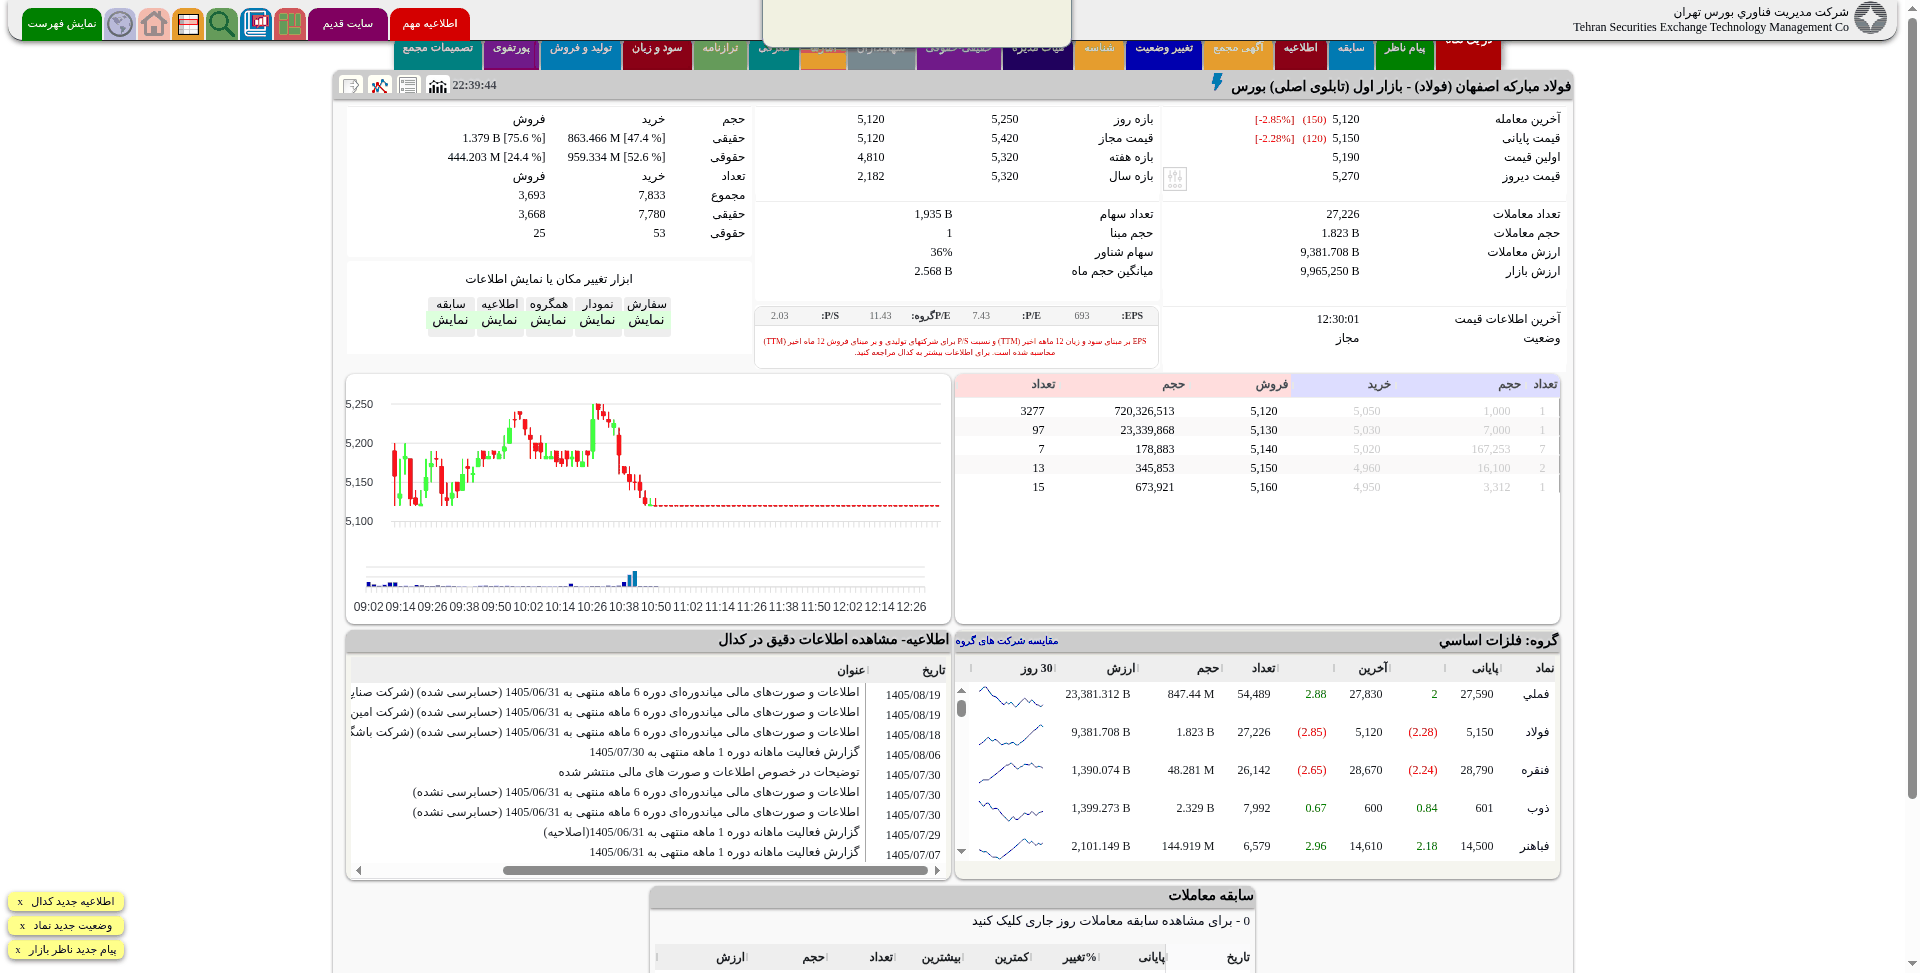

### Section 5: tab سابقه

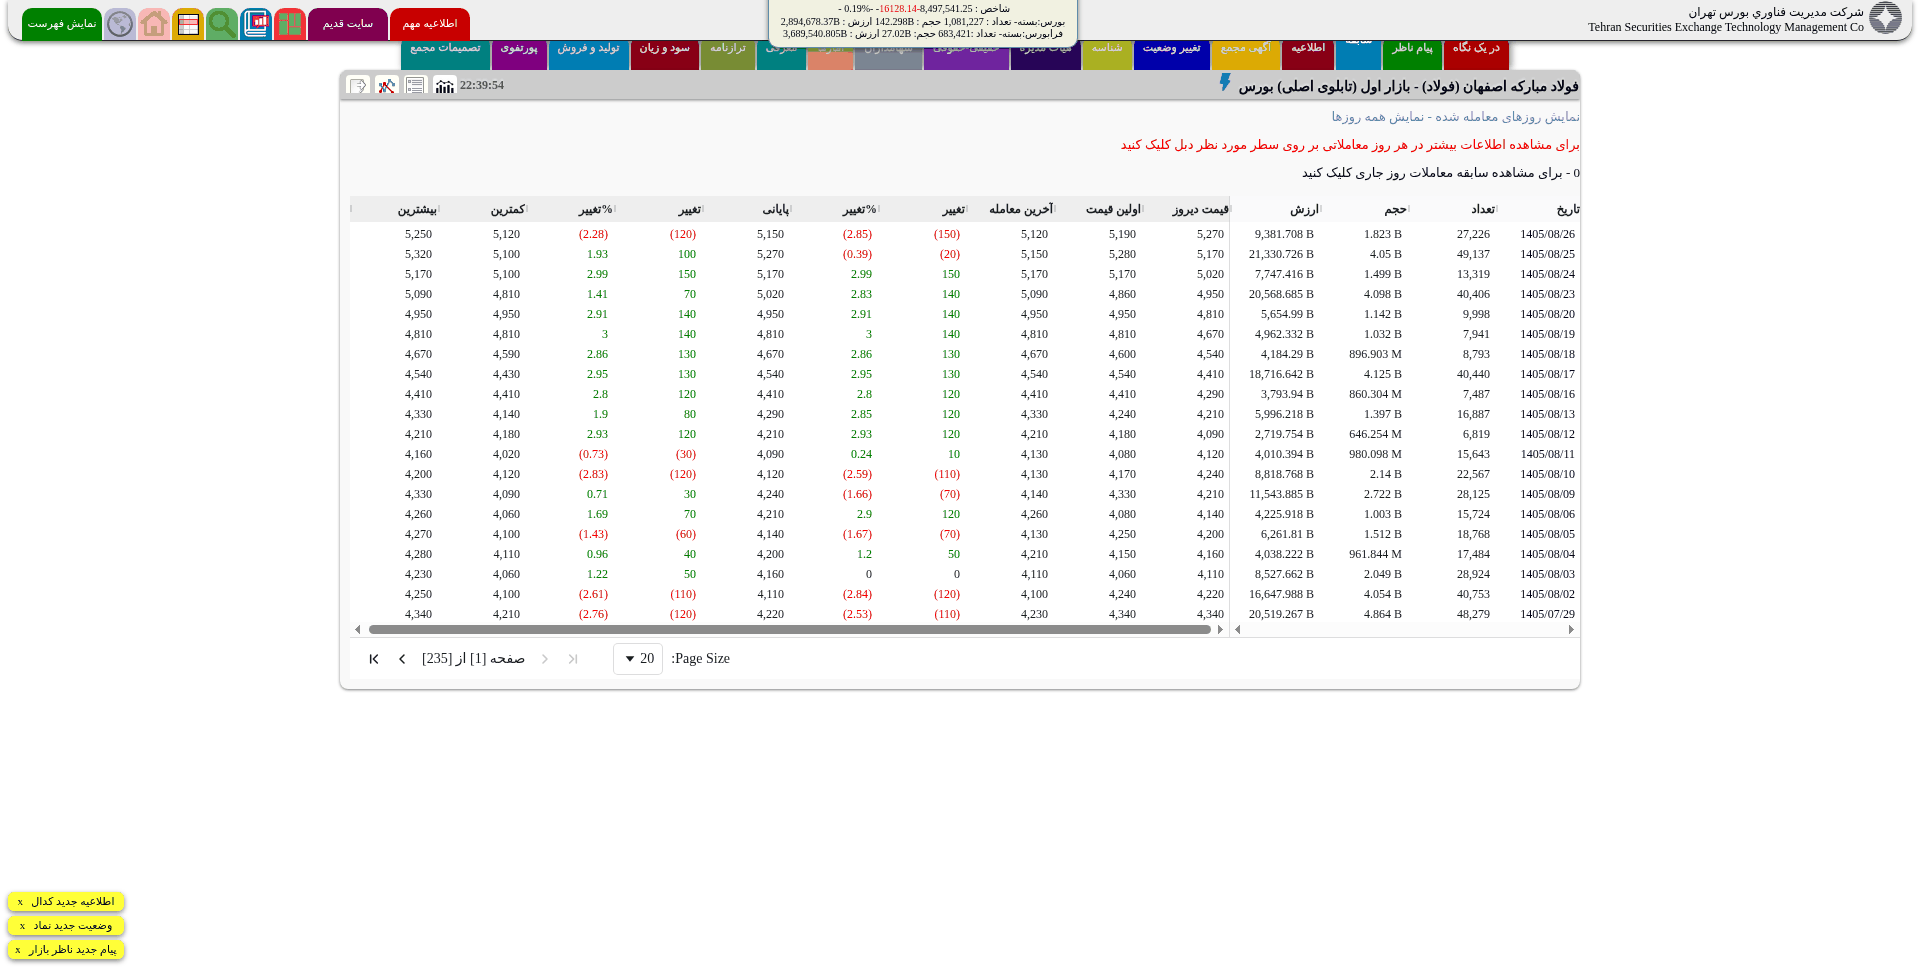

### Section 6: tab حقیقی-حقوقی

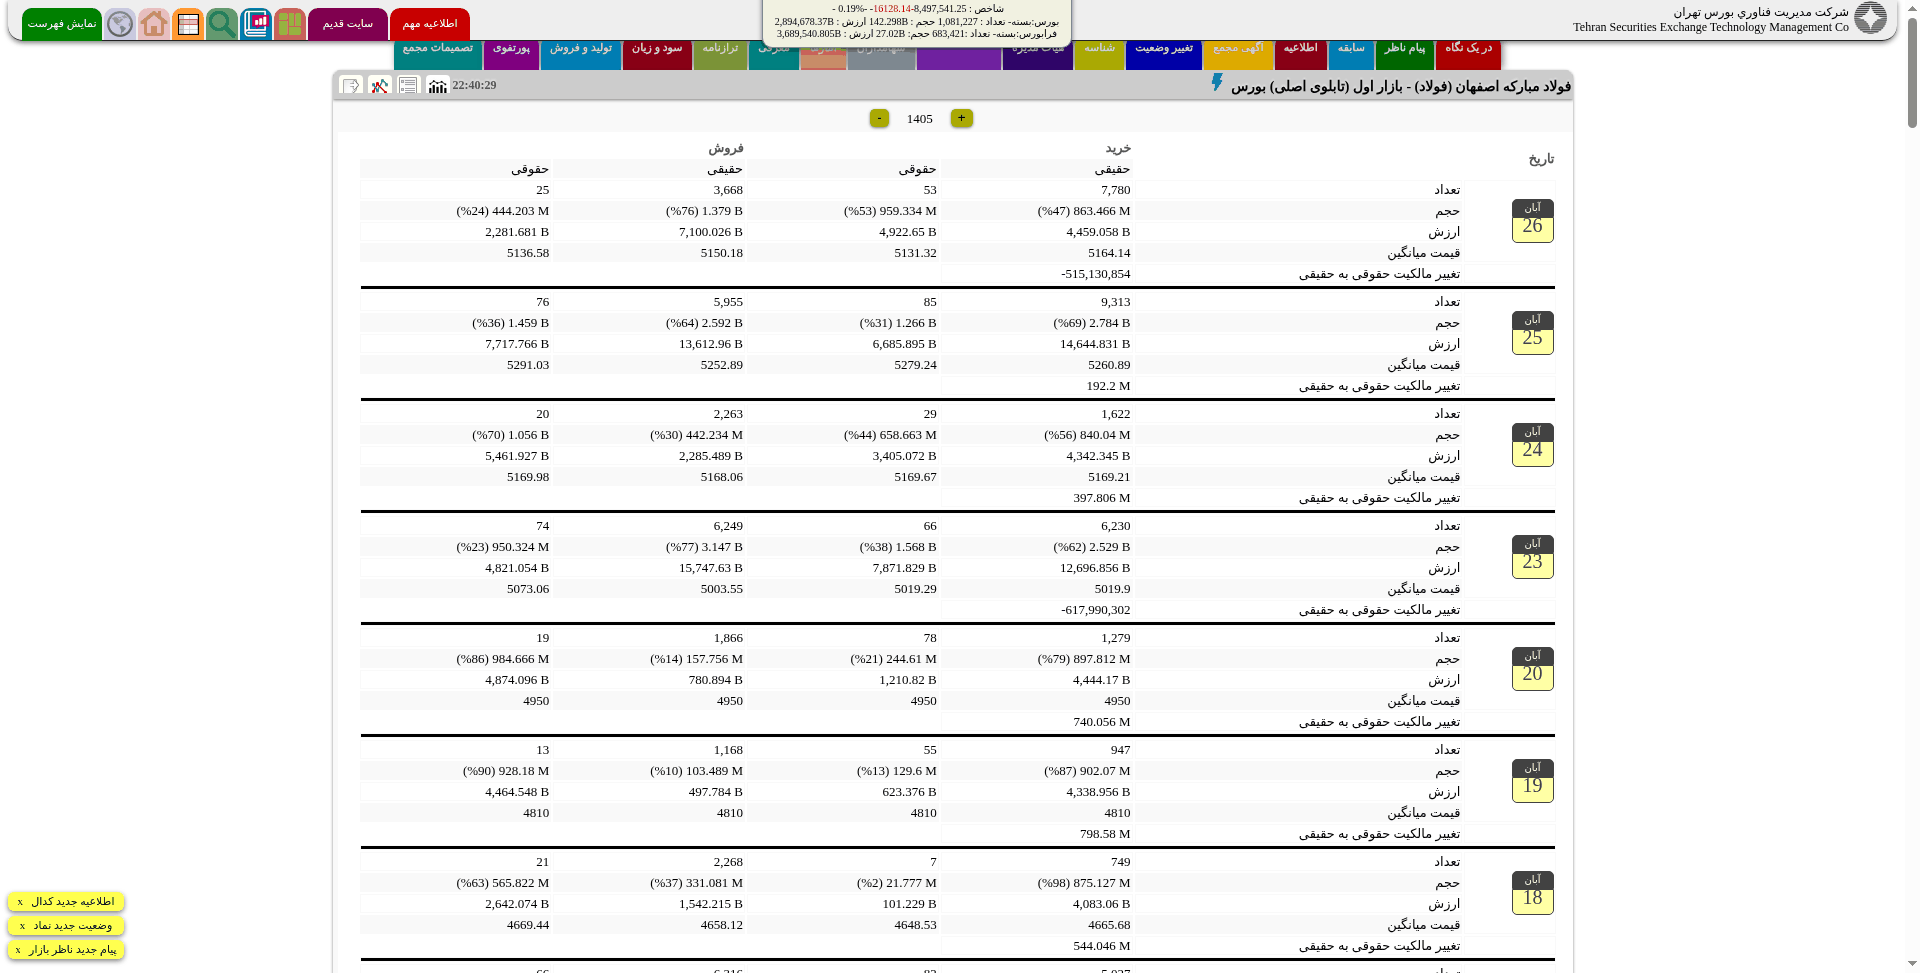

### Section 7: tab سهامداران

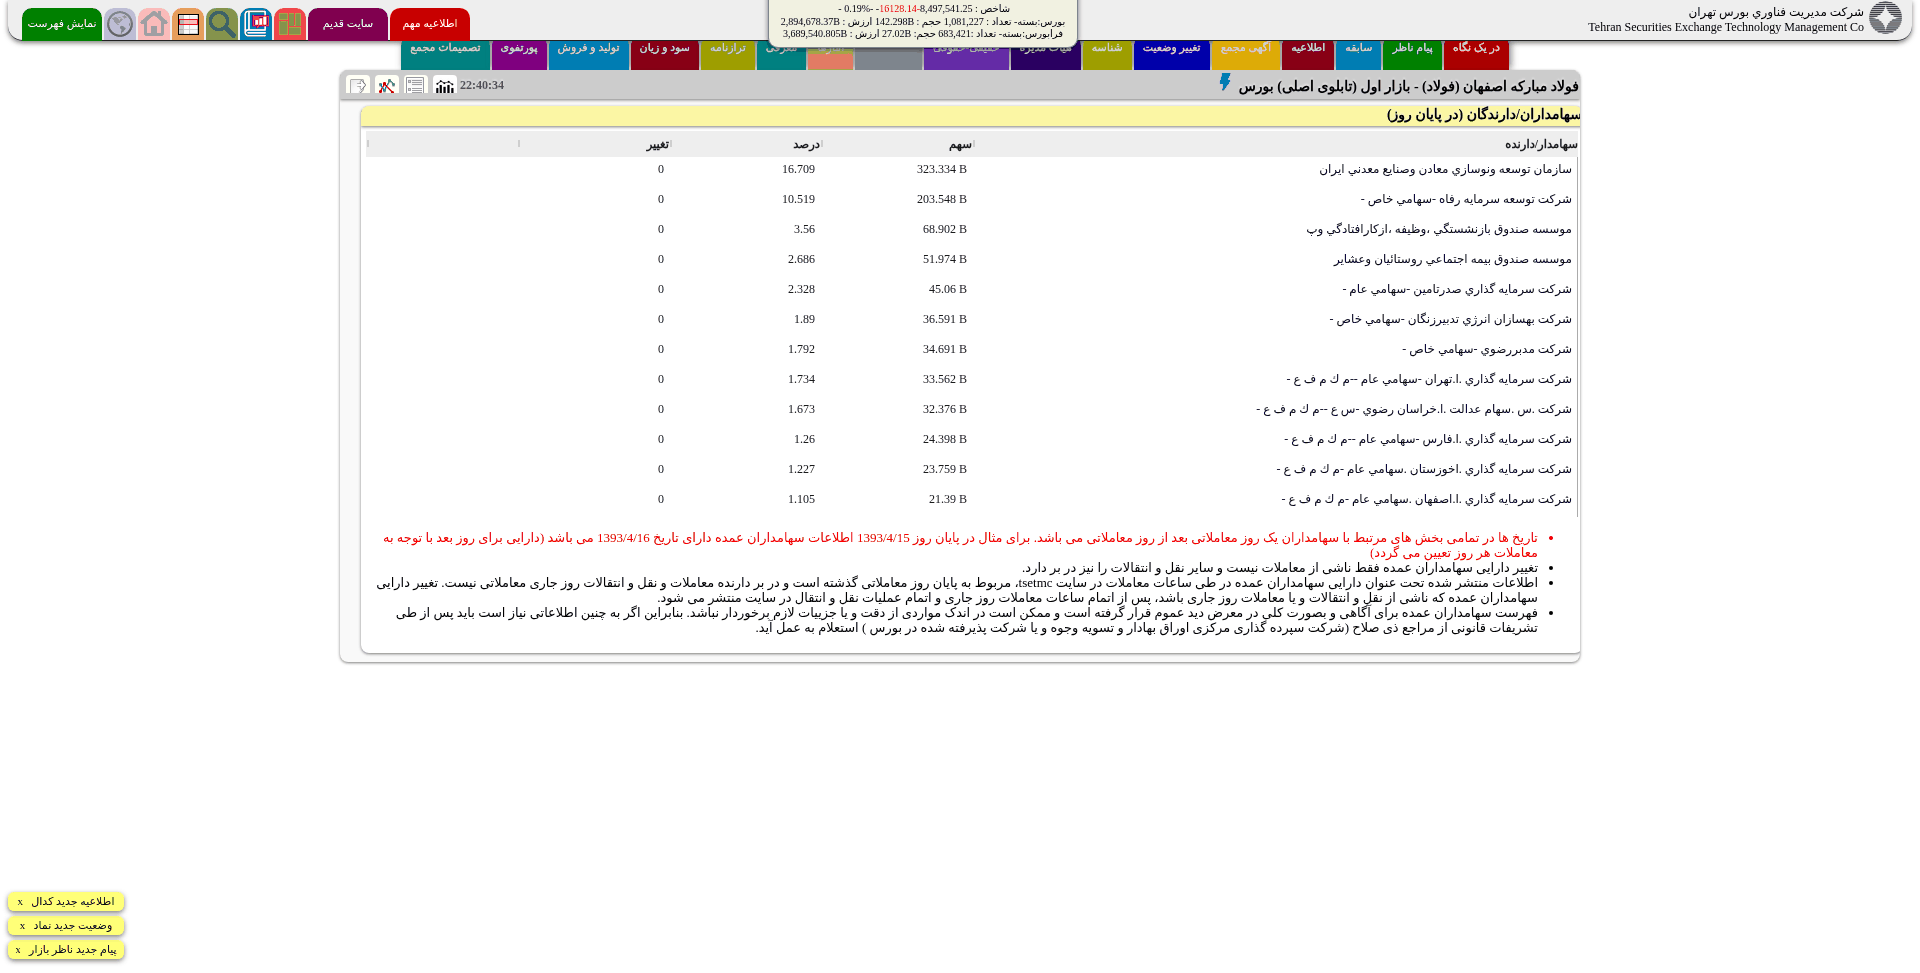

### Section 8: tab معرفی

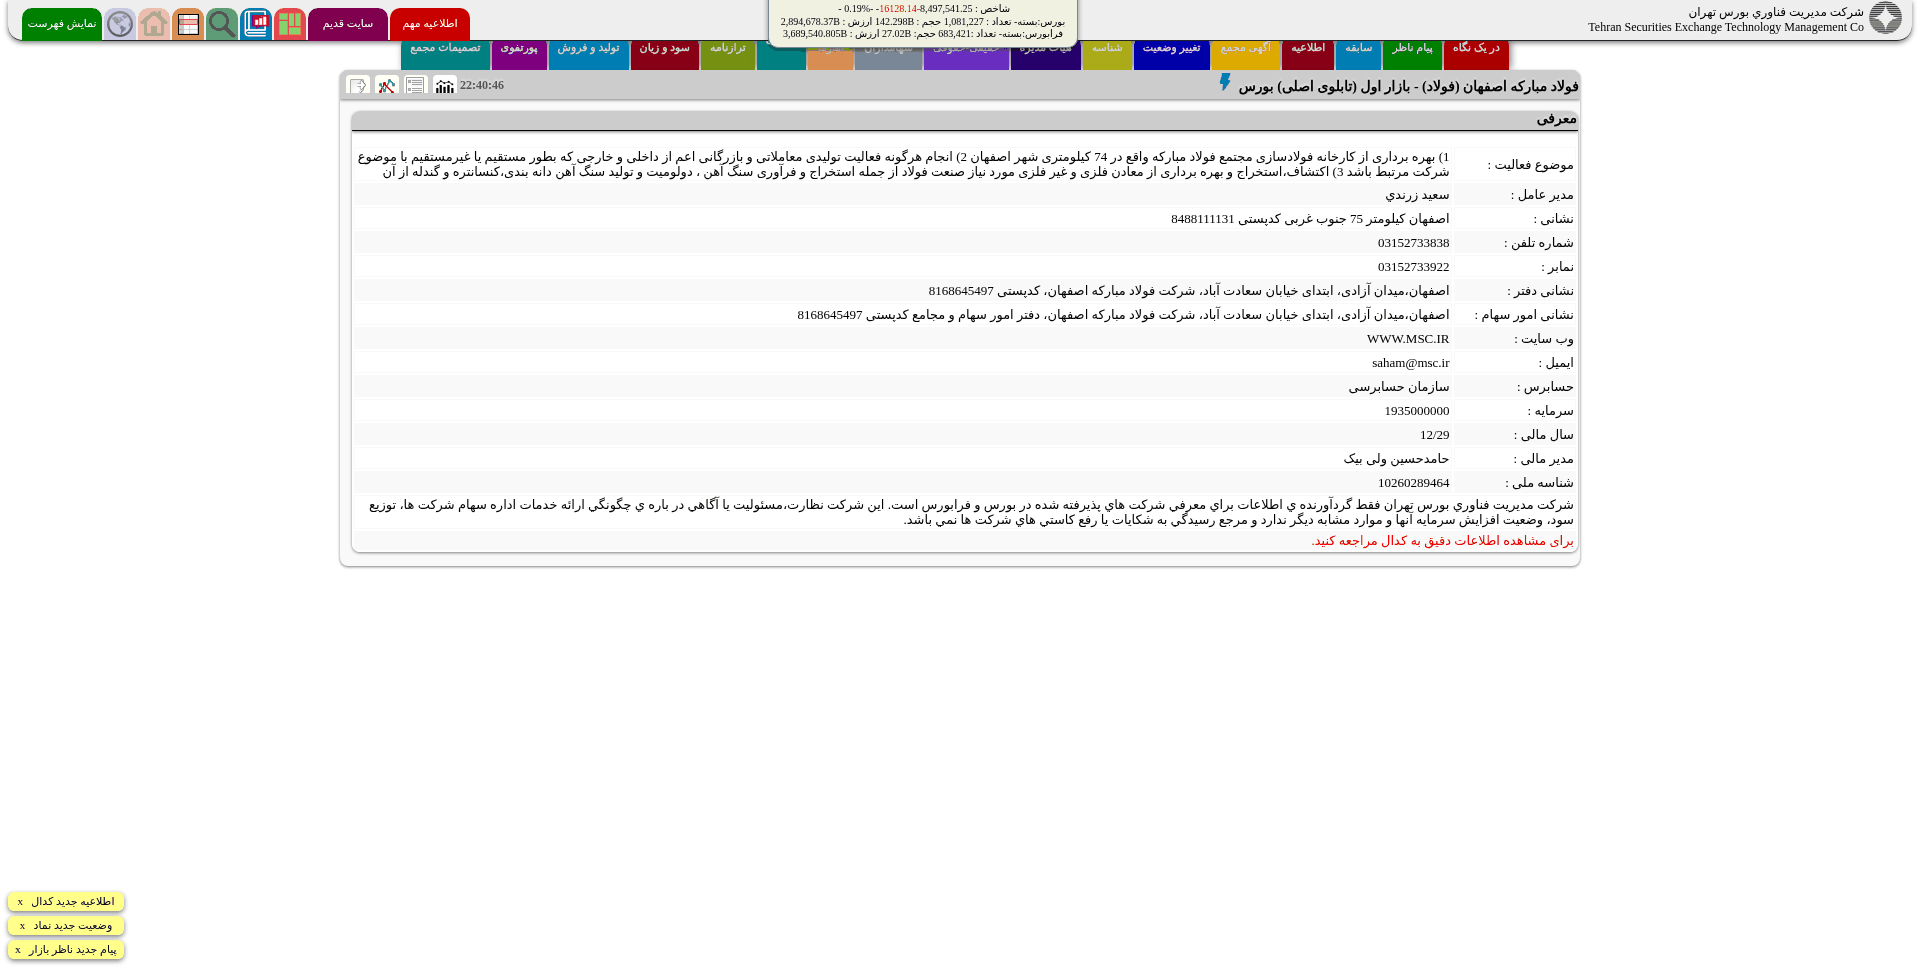

### Section 8: tab شناسه

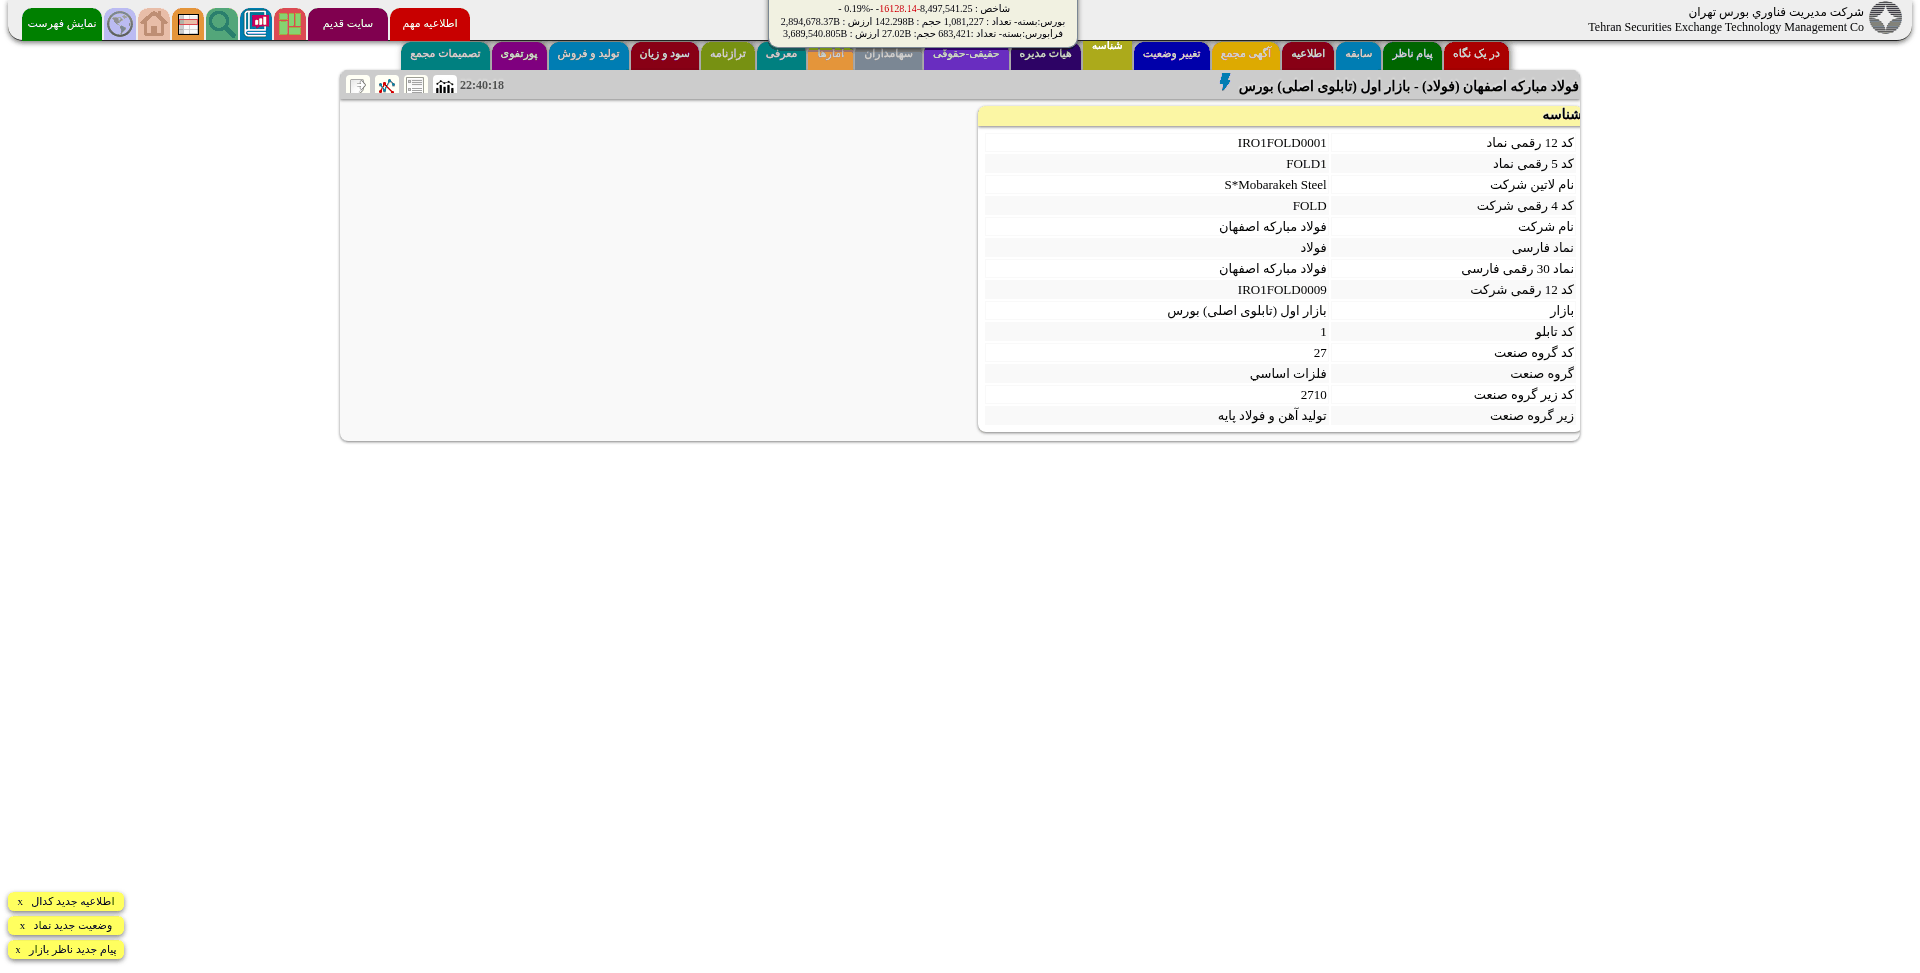

### Section 9: اطلاعات تکمیلی > ریز معاملات

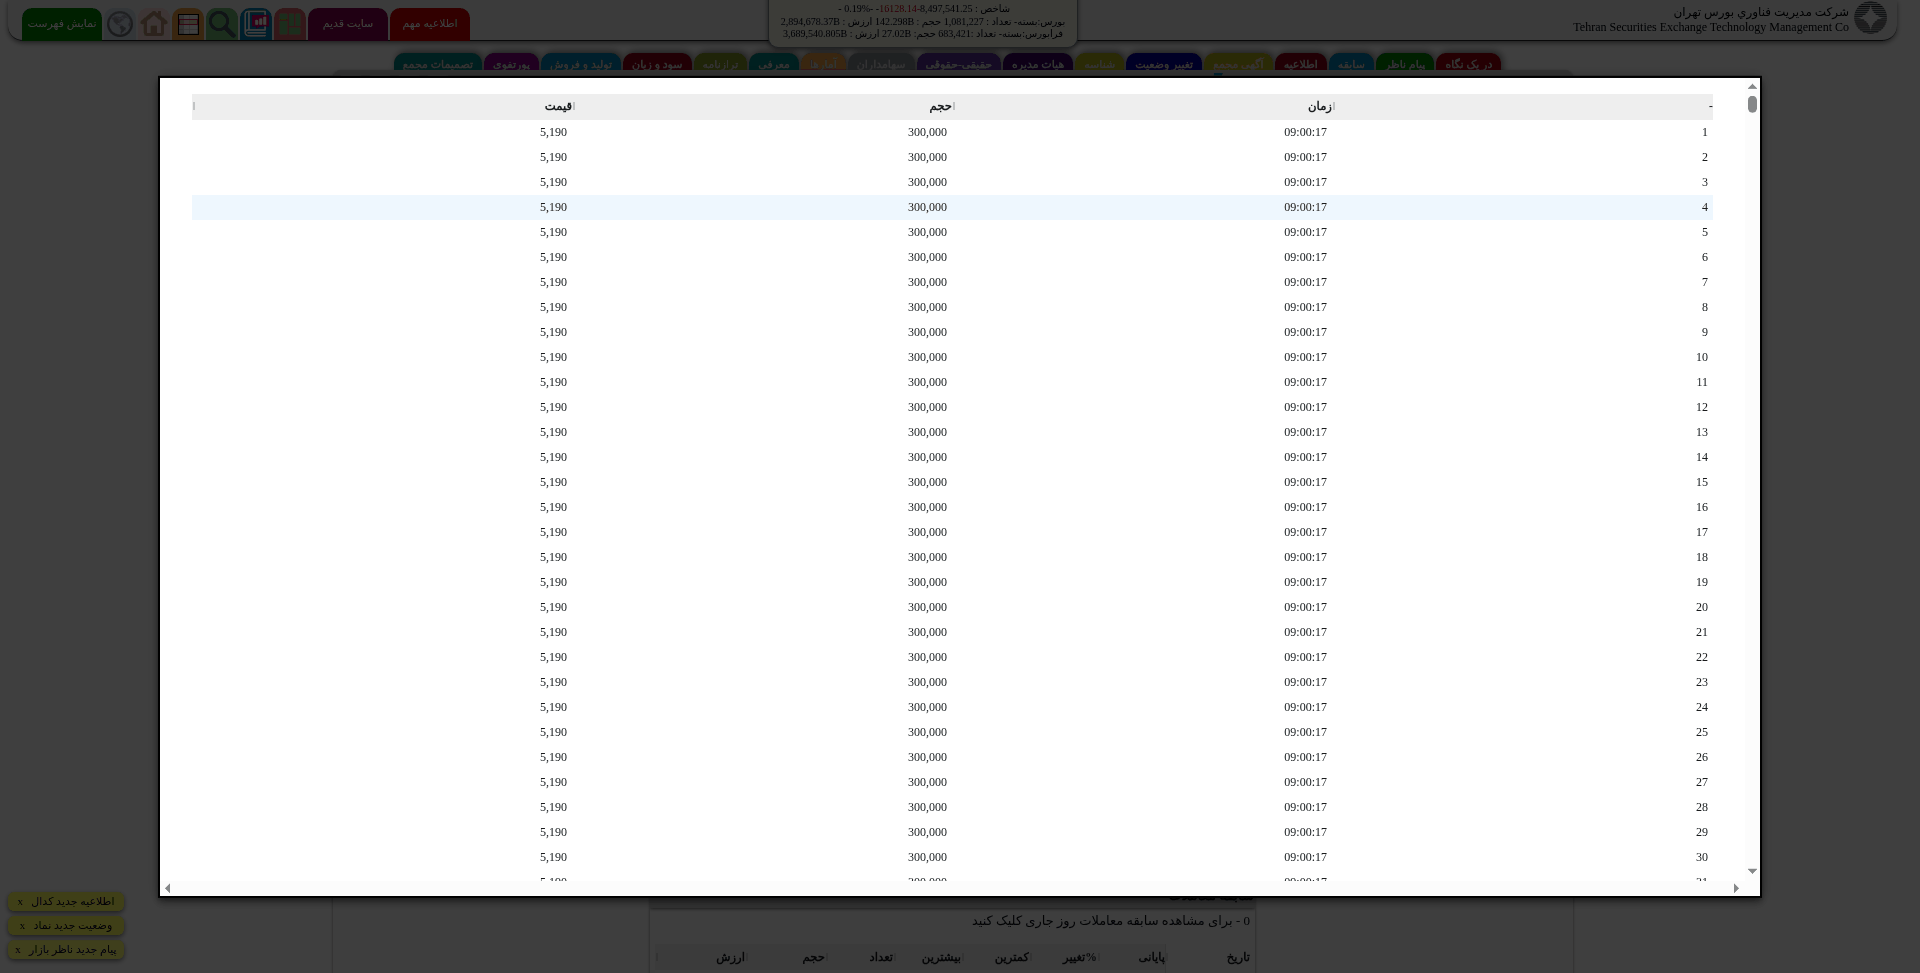

### Section 10: page of one day (1405/08/24), tab در یک نگاه
https://www.tsetmc.com/History/46348559193224090/20261115

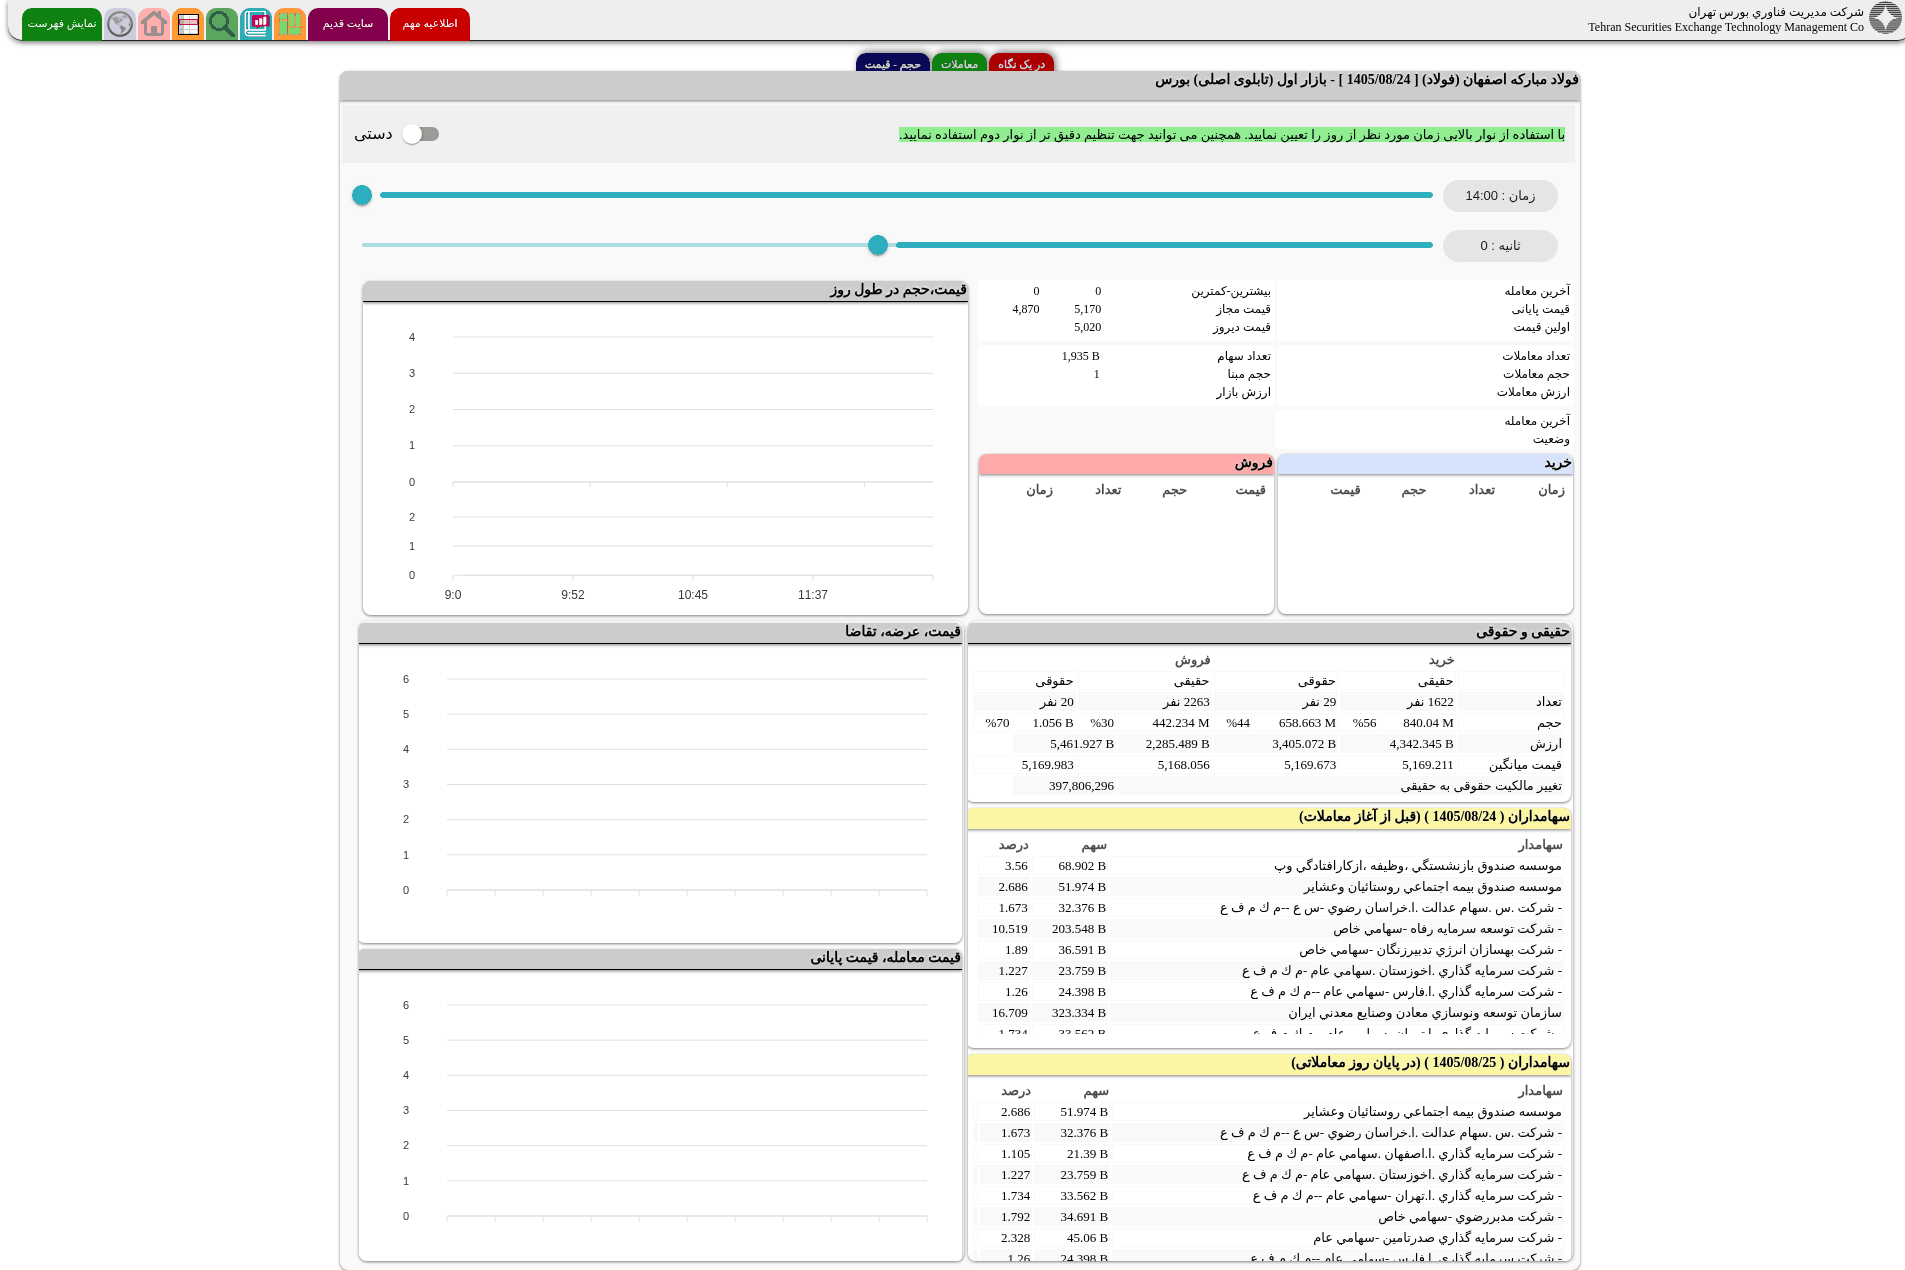

### Section 10: page of one day, tab معاملات

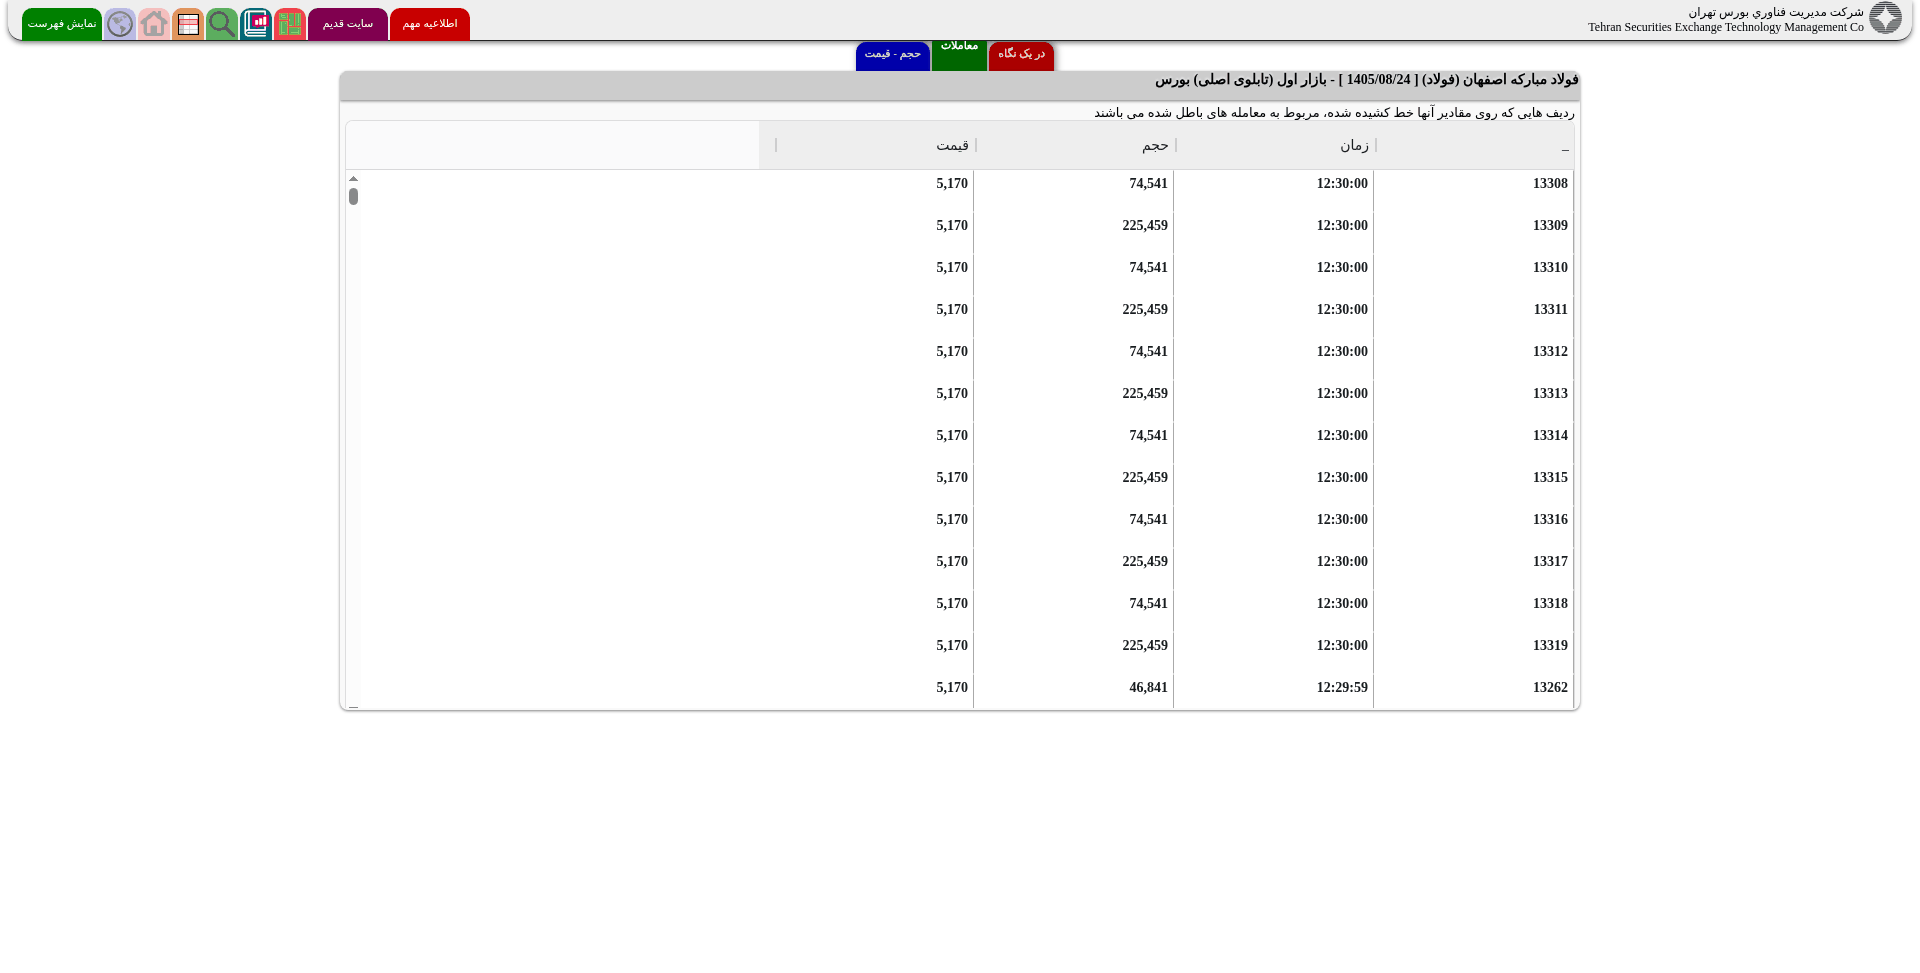

### Section 11: page of the fund یاقوت
https://www.tsetmc.com/instInfo/1438514795814416

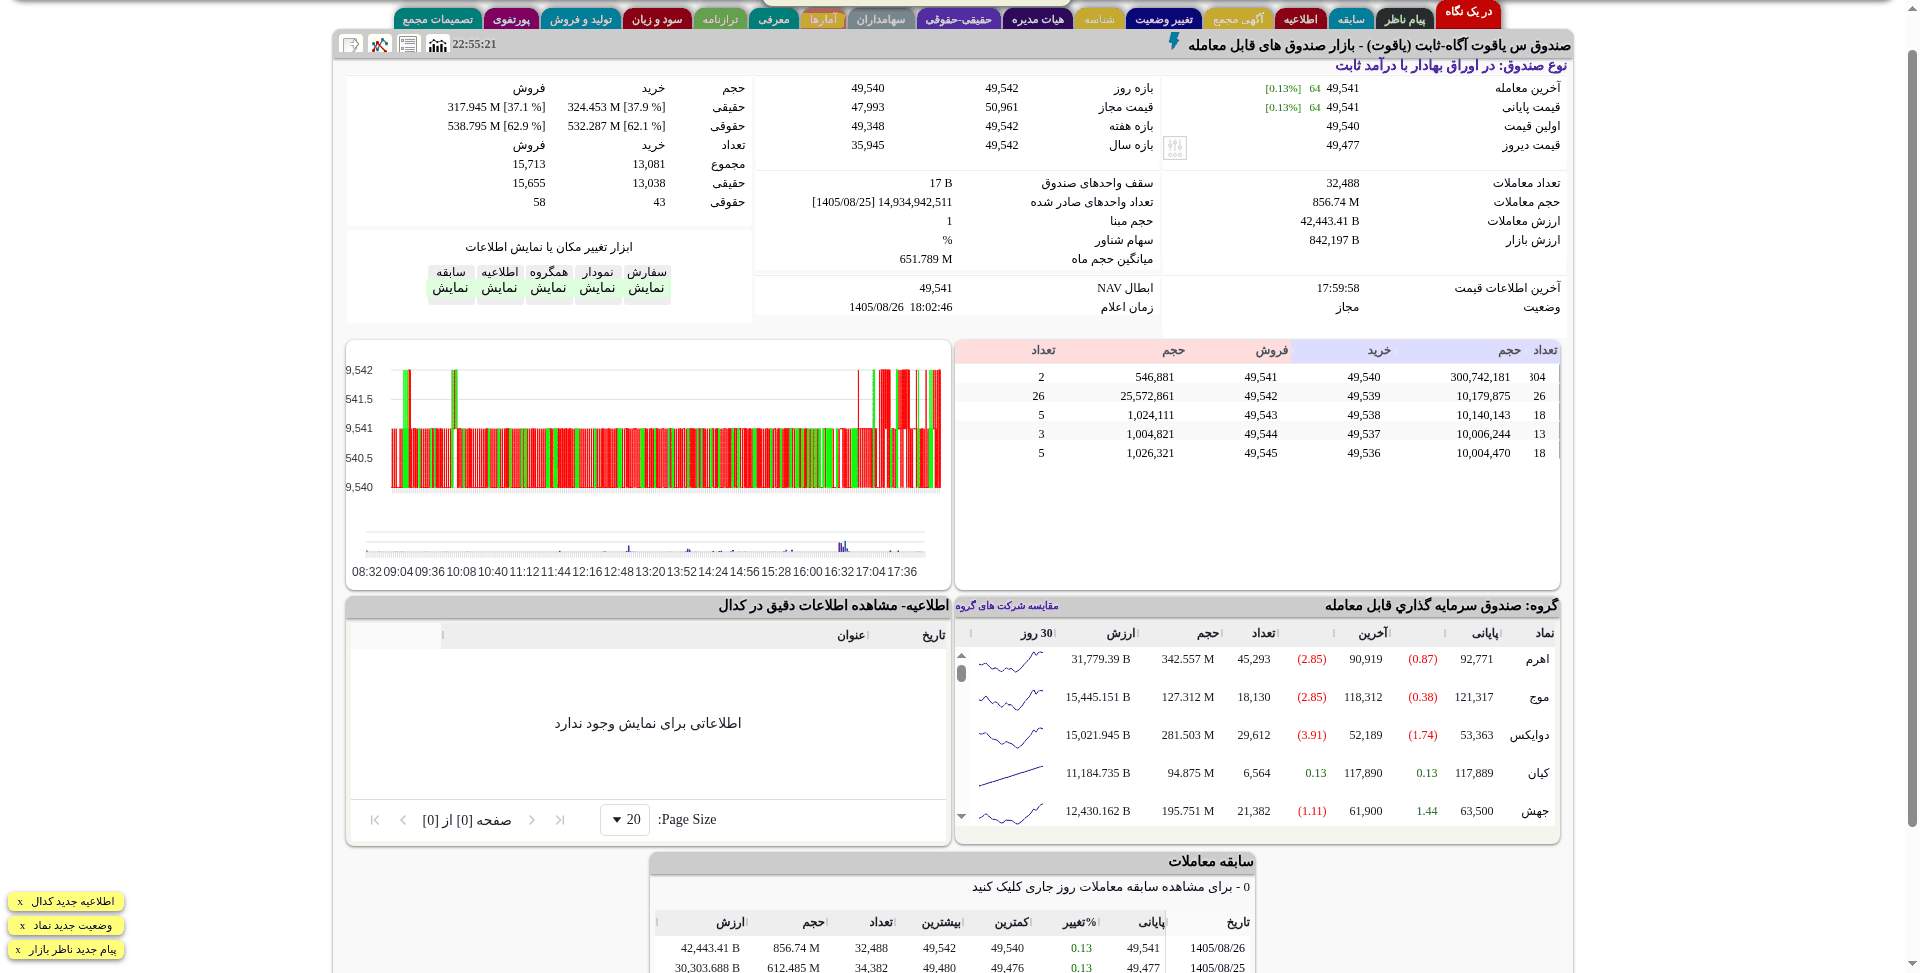

### Section 12: page of شاخص کل
https://www.tsetmc.com/IndexInfo/32097828799138957

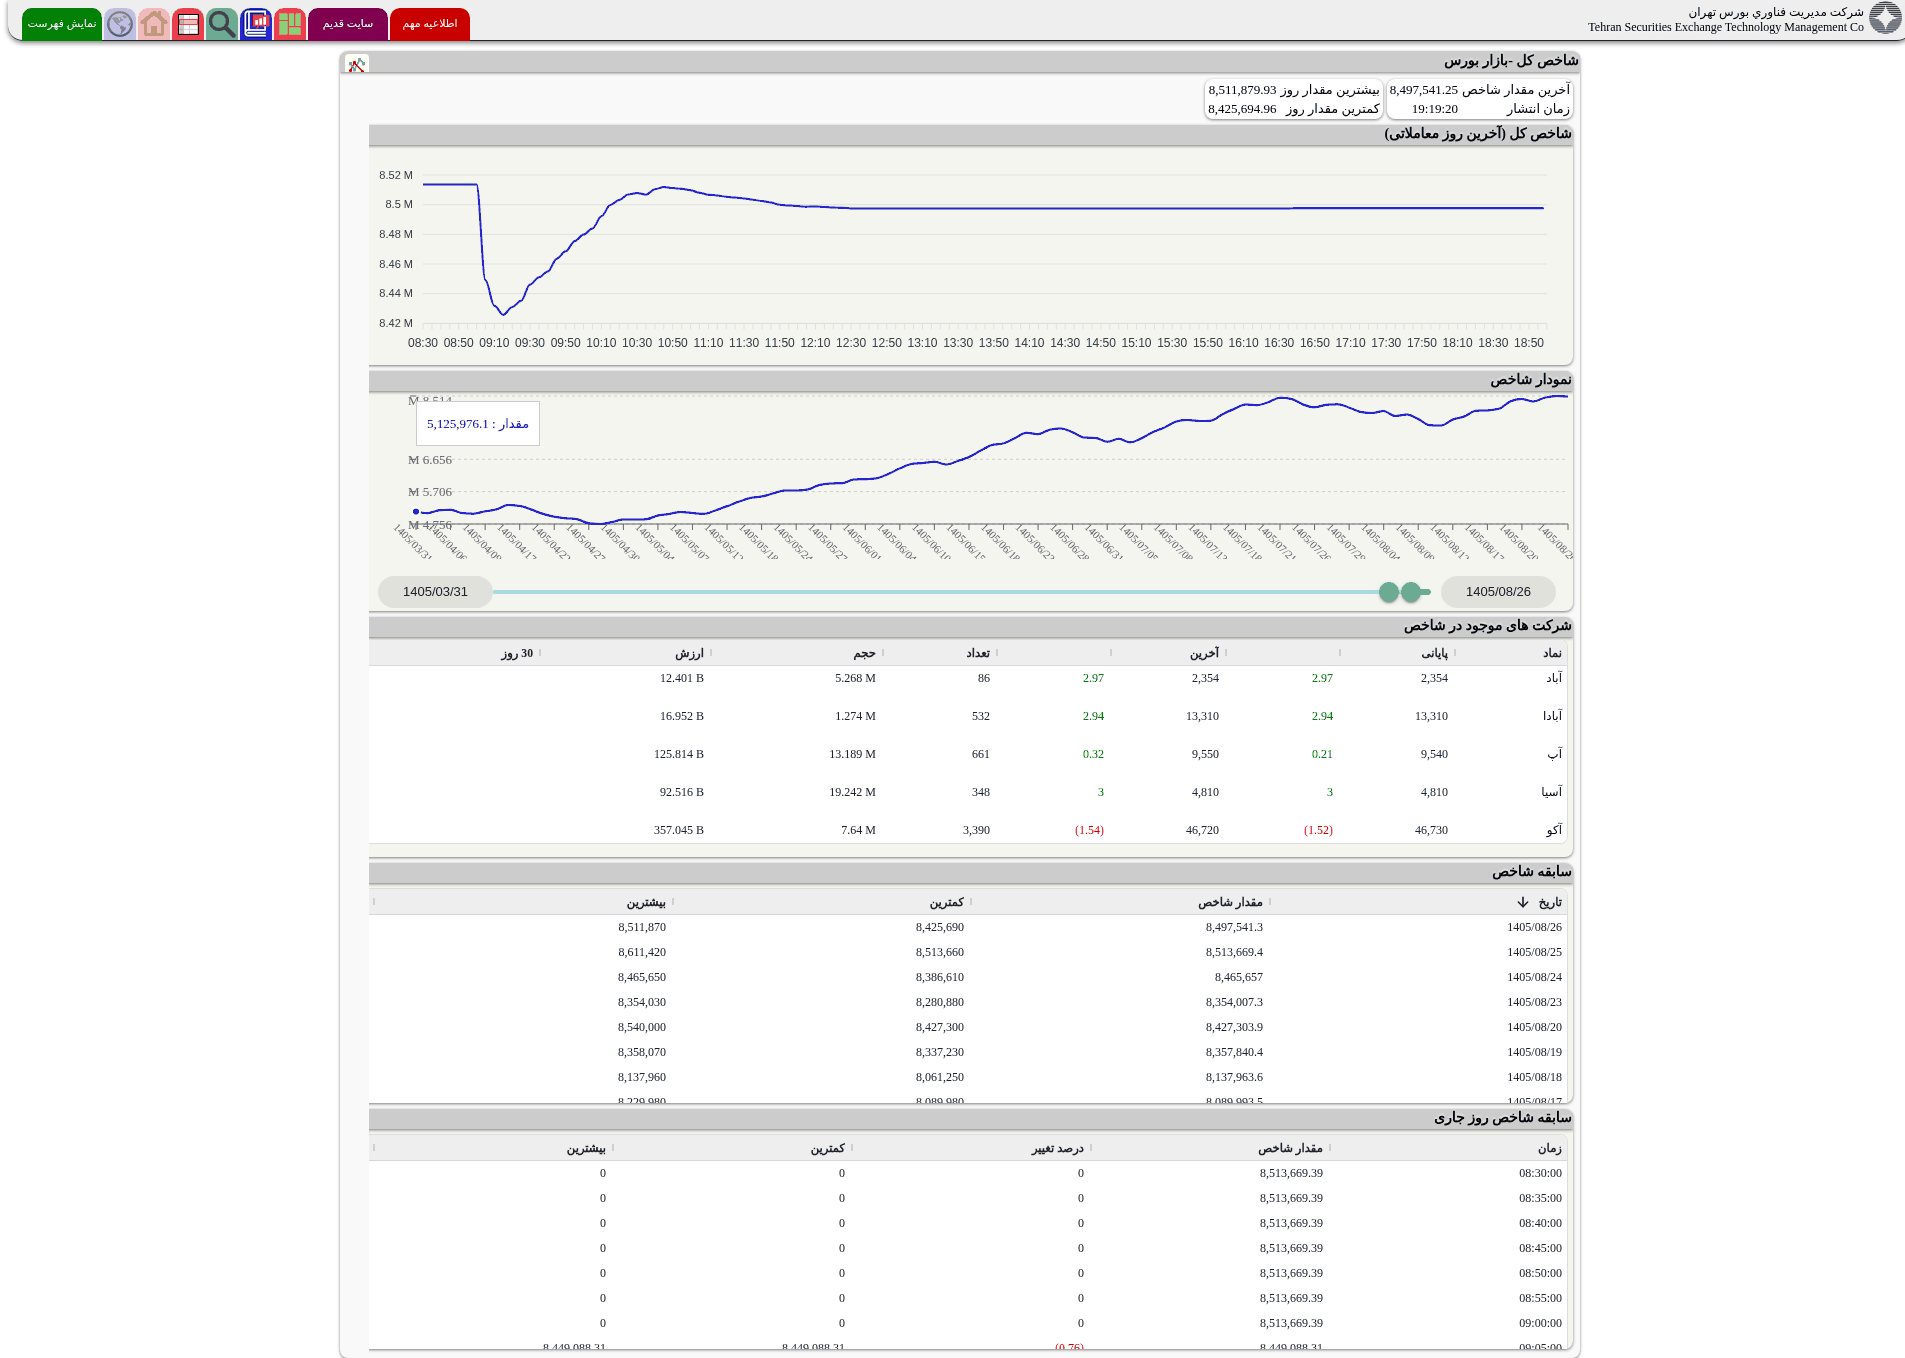

### Section 13: market watch
https://www.tsetmc.com/marketwatchnew

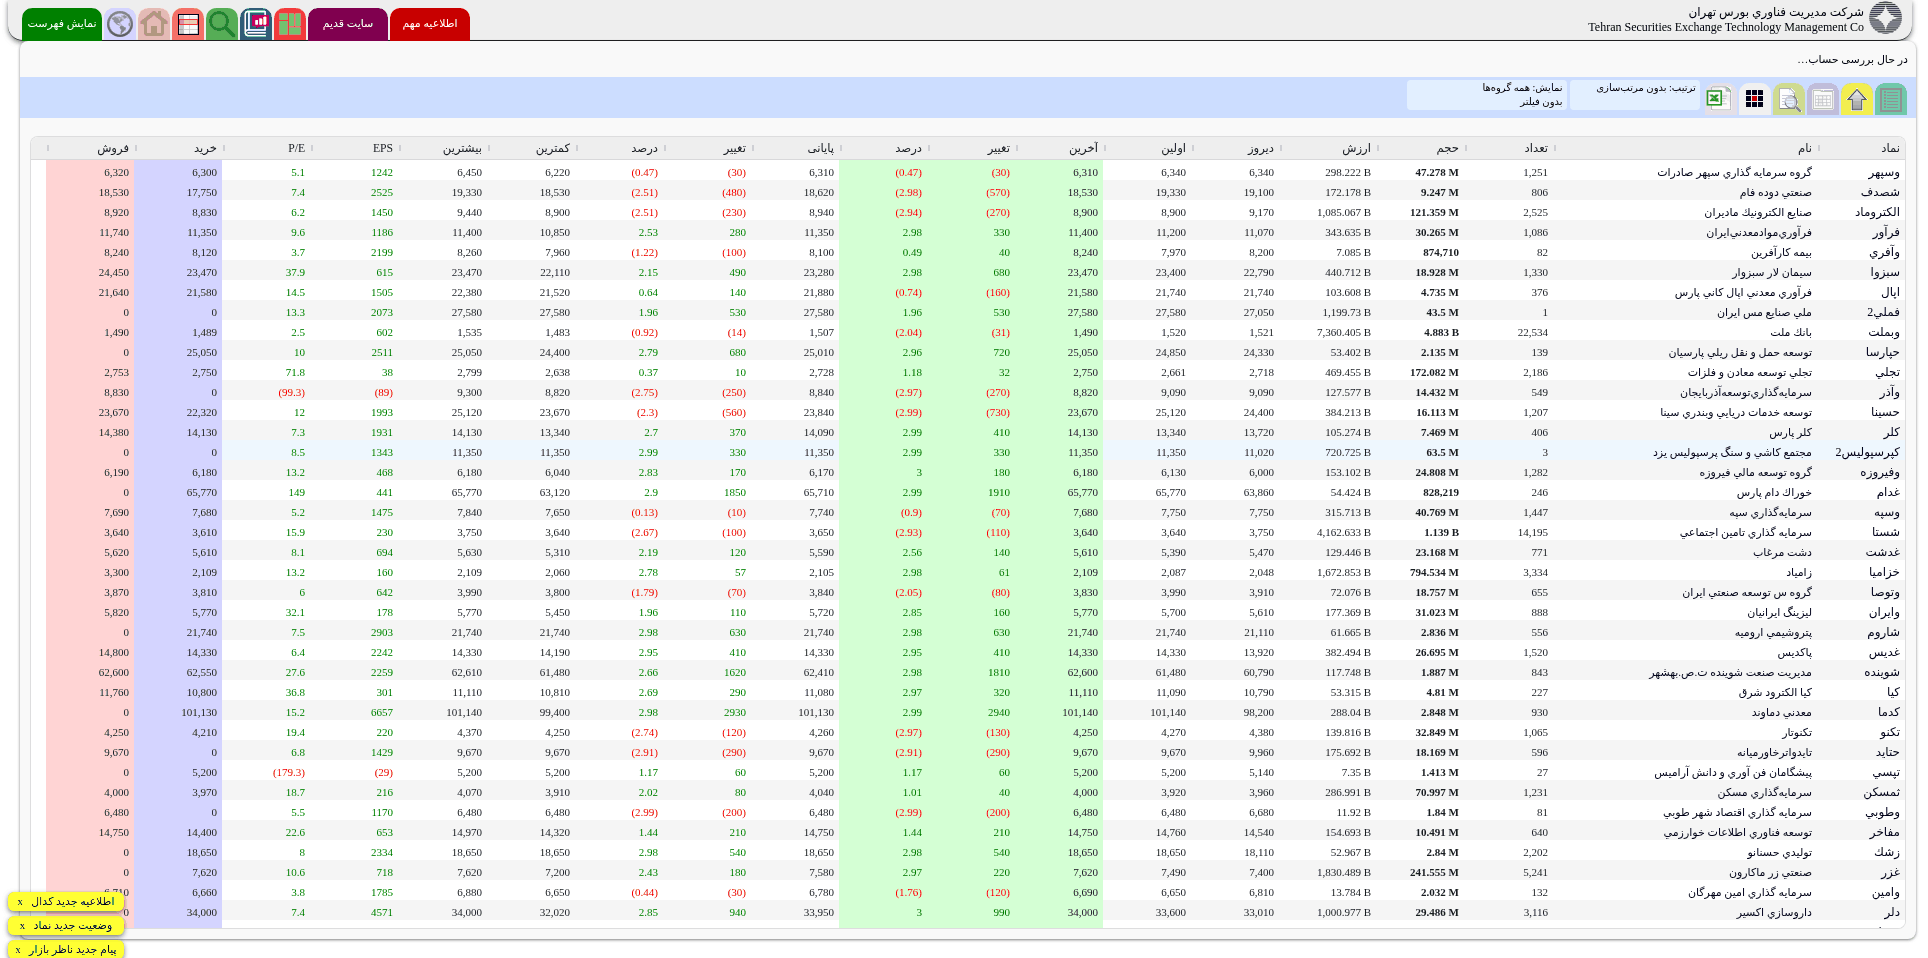

### Section 14: tab آمارها

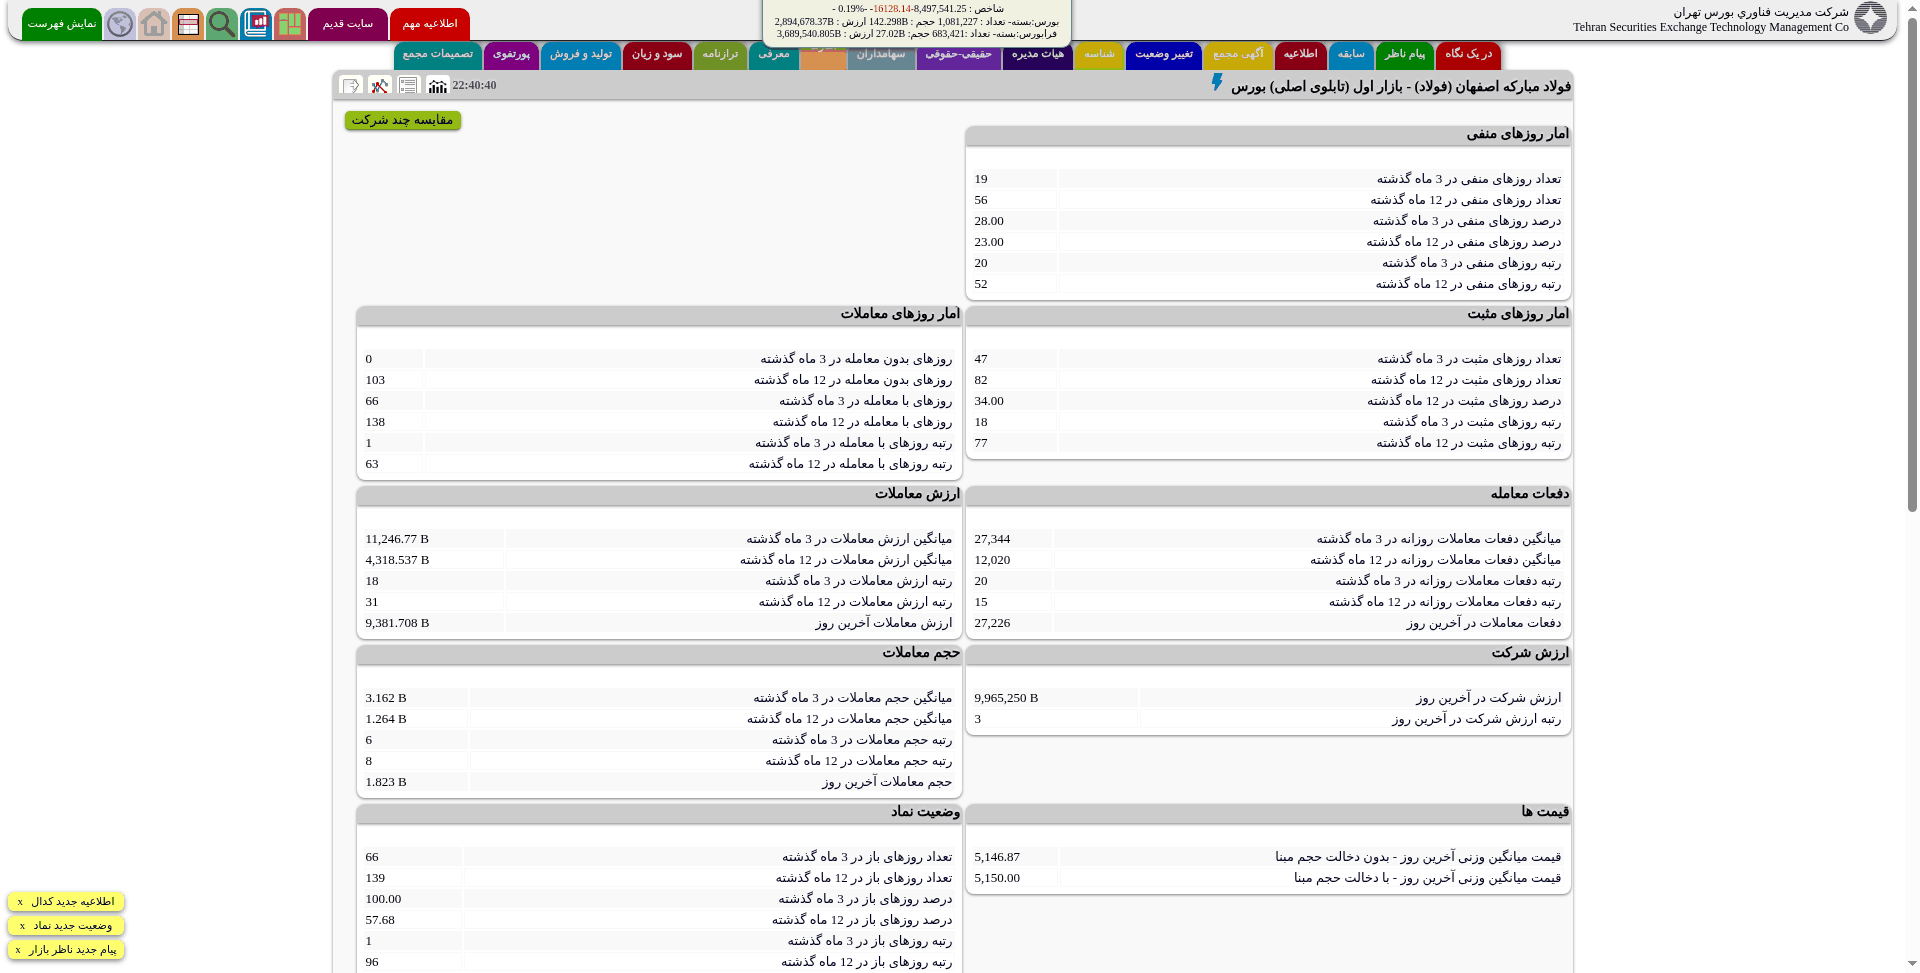